<a href="https://colab.research.google.com/github/Saidislom2001/Projects/blob/main/AnimalFaceRecognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opendatasets legacy-cgi --quiet
import opendatasets as od
dataset_url = 'https://www.kaggle.com/datasets/andrewmvd/animal-faces'
od.download(dataset_url)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: saidislomanvar
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/animal-faces


100%|██████████| 696M/696M [00:06<00:00, 113MB/s]


In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torch.optim import Adam
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import pandas as pd
import os

device = 'cuda' if torch.cuda.is_available() else "cpu"
print("Device available: ", device)

Device available:  cuda


In [ ]:
image_path = []
labels = []

for i in os.listdir("/content/animal-faces/afhq"):
  for label in os.listdir(f"/content/animal-faces/afhq/{i}"):
    for image in os.listdir(f"/content/animal-faces/afhq/{i}/{label}"):
      image_path.append(f"/content/animal-faces/afhq/{i}/{label}/{image}")
      labels.append(label)

data_df = pd.DataFrame(zip(image_path, labels), columns=["image_path", "labels"])
data_df.head()



,image_path,labels
0,/content/animal-faces/afhq/val/cat/pixabay_cat...,cat
1,/content/animal-faces/afhq/val/cat/pixabay_cat...,cat
2,/content/animal-faces/afhq/val/cat/pixabay_cat...,cat
3,/content/animal-faces/afhq/val/cat/pixabay_cat...,cat
4,/content/animal-faces/afhq/val/cat/pixabay_cat...,cat


In [ ]:
data_df["labels"].unique()

array(['cat', 'wild', 'dog'], dtype=object)

Split Data


In [40]:
from torchvision import transforms

# Если переменные разделения были утеряны или сброшены, пересоздаем их
try:
    if train is None or val is None or test is None:
        raise NameError
except NameError:
    train = data_df.sample(frac=0.7, random_state=42)
    test = data_df.drop(train.index)
    val = test.sample(frac=0.5, random_state=42)
    test = test.drop(val.index)

# Аугментация для тренировочной выборки
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.ConvertImageDtype(torch.float)
])

# Для валидации и теста оставляем только приведение размеров
val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.ConvertImageDtype(torch.float)
])

# Пересоздаем датасеты с новыми трансформациями
train_dataset = CustomDataset(train, transform=train_transform)
val_dataset = CustomDataset(val, transform=val_transform)
test_dataset = CustomDataset(test, transform=val_transform)

# Обновляем загрузчики данных
train_loader = DataLoader(train_dataset, batch_size=BANCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BANCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BANCH_SIZE, shuffle=False)

In [41]:
class CustomDataset(Dataset):
  def __init__(self, dataframe, transform = None):
    self.dataframe = dataframe
    self.transform = transform
    self.labels = torch.tensor(label_encoder.transform(dataframe["labels"])).to(device)

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self, idx):
    img_path = self.dataframe.iloc[idx, 0]
    image = Image.open(img_path)
    label = self.labels[idx]
    if self.transform:
      image = self.transform(image).to(device)
    return image, label

In [42]:
train_dataset = CustomDataset(train, transform = transform)
test_dataset = CustomDataset(test, transform = transform)
val_dataset = CustomDataset(val, transform = transform)

In [43]:
train_dataset.__getitem__(2)

(tensor([[[0.4039, 0.4078, 0.4078,  ..., 0.9922, 0.9961, 1.0000],
          [0.3882, 0.3686, 0.3922,  ..., 0.9843, 0.9882, 0.9922],
          [0.3765, 0.3647, 0.3804,  ..., 0.9804, 0.9843, 0.9843],
          ...,
          [0.6980, 0.7098, 0.7216,  ..., 0.9765, 0.9686, 0.9686],
          [0.6980, 0.6980, 0.7059,  ..., 0.9725, 0.9725, 0.9529],
          [0.7137, 0.7020, 0.6824,  ..., 0.9725, 0.9686, 0.9529]],
 
         [[0.4353, 0.4392, 0.4471,  ..., 0.9843, 0.9804, 0.9804],
          [0.4078, 0.3882, 0.4235,  ..., 0.9725, 0.9686, 0.9647],
          [0.3725, 0.3686, 0.3922,  ..., 0.9608, 0.9529, 0.9451],
          ...,
          [0.4549, 0.4667, 0.4784,  ..., 0.6745, 0.6667, 0.6667],
          [0.5020, 0.5020, 0.5059,  ..., 0.6706, 0.6706, 0.6510],
          [0.5490, 0.5373, 0.5176,  ..., 0.6706, 0.6667, 0.6510]],
 
         [[0.5412, 0.5490, 0.5647,  ..., 0.9529, 0.9529, 0.9529],
          [0.4784, 0.4667, 0.5059,  ..., 0.9333, 0.9333, 0.9333],
          [0.4000, 0.4000, 0.4275,  ...,

In [ ]:
label_encoder.inverse_transform([2])


array(['wild'], dtype=object)

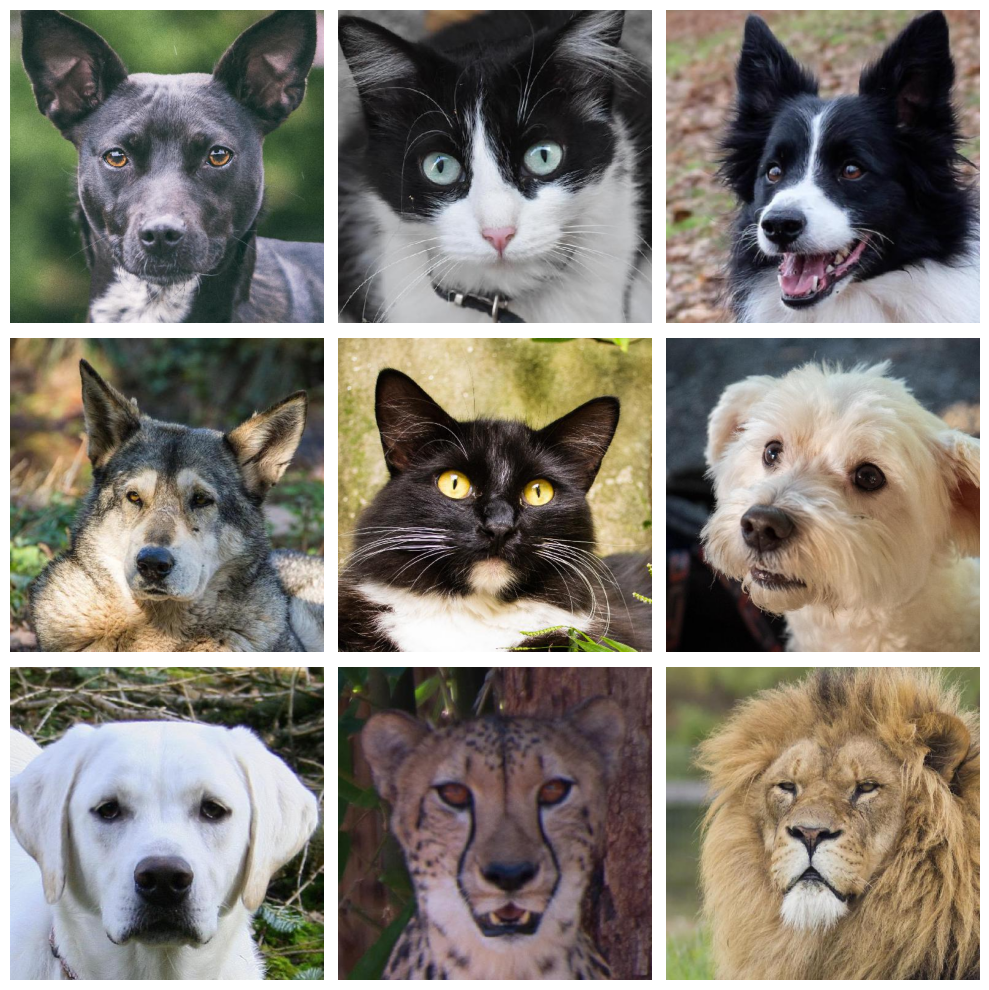

In [ ]:
n_rows = 3
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 10))

for i in range(n_rows):
  for j in range(n_cols):
    image = Image.open(data_df.sample(n=2)["image_path"].iloc[1]).convert("RGB")
    axes[i, j].imshow(image)
    axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
LR = 1e-4
BANCH_SIZE = 16
EPOCHS = 10


In [ ]:
train_loader = DataLoader(train_dataset, batch_size=BANCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BANCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BANCH_SIZE, shuffle=True)


In [47]:
class Net(nn.Module):
  def __init__(self):
    super(Net, self).__init__()

    self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
    self.bn1 = nn.BatchNorm2d(32)

    self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
    self.bn2 = nn.BatchNorm2d(64)

    self.conv3 = nn.Conv2d(in_channels=64, out_channels=138, kernel_size=3, padding=1)
    self.bn3 = nn.BatchNorm2d(138)

    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.relu = nn.ReLU()
    self.flatten = nn.Flatten()

    self.linear = nn.Linear(138*16*16, 128)
    self.dropout = nn.Dropout(p=0.5) # Исключаем 50% нейронов при обучении
    self.output = nn.Linear(128, len(data_df["labels"].unique()))

  def forward(self, x):
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.pool(x)

    x = self.conv2(x)
    x = self.bn2(x)
    x = self.relu(x)
    x = self.pool(x)

    x = self.conv3(x)
    x = self.bn3(x)
    x = self.relu(x)
    x = self.pool(x)

    x = self.flatten(x)
    x = self.linear(x)
    x = self.relu(x)
    x = self.dropout(x) # Применяем регуляризацию
    x = self.output(x)
    return x

In [48]:
# Пересоздаем модель и оптимизатор, используя актуальный класс Net из ячейки v4kr_j6ADijx
model = Net().to(device)
optimizer = Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

from torchsummary import summary
summary(model, (3, 128, 128))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 138, 32, 32]          79,626
      BatchNorm2d-10          [-1, 138, 32, 32]             276
             ReLU-11          [-1, 138, 32, 32]               0
        MaxPool2d-12          [-1, 138, 16, 16]               0
          Flatten-13                [-1, 35328]               0
           Linear-14                  [

In [49]:
total_los_train_plot = []
total_los_val_plot = []
total_acc_train_plot = []
total_acc_val_plot = []

for epoch in range(EPOCHS):
  total_acc_train = 0
  total_loss_train = 0
  total_acc_val = 0
  total_loss_val = 0

  for inputs, labels in train_loader:
    optimizer.zero_grad()
    outputs = model(inputs)
    train_loss = criterion(outputs, labels)
    total_loss_train += train_loss.item()
    train_loss.backward()

    train_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
    total_acc_train += train_acc

    optimizer.step()

  with torch.inference_mode():
    for inputs, labels in val_loader:
      outputs = model(inputs)
      val_loss = criterion(outputs, labels)
      total_loss_val += val_loss.item()
      val_acc = (torch.argmax(outputs, axis = 1) == labels).sum().item()
      total_acc_val += val_acc

  total_los_train_plot.append(round(total_loss_train / len(train_loader), 3))
  total_los_val_plot.append(round(total_loss_val / len(val_loader), 3))
  total_acc_train_plot.append(round(total_acc_train / len(train_dataset) * 100, 3))
  total_acc_val_plot.append(round(total_acc_val / len(val_dataset) * 100, 3))

  print(f'''Epoch: {epoch+1}/{EPOCHS}, Train Loss: {round(total_loss_train / len(train_loader), 3)}, Train Accuracy {round(total_acc_train / len(train_dataset) * 100, 3)}%
      Validation Loss {round(total_loss_val / len(val_loader), 3)}, Validation Accuracy {round(total_acc_val / len(val_dataset) * 100, 3)}%''')

Epoch: 1/10, Train Loss: 0.517, Train Accuracy 78.744%
      Validation Loss 0.308, Validation Accuracy 88.926%
Epoch: 2/10, Train Loss: 0.253, Train Accuracy 91.294%
      Validation Loss 0.207, Validation Accuracy 92.975%
Epoch: 3/10, Train Loss: 0.192, Train Accuracy 93.287%
      Validation Loss 0.2, Validation Accuracy 92.769%
Epoch: 4/10, Train Loss: 0.161, Train Accuracy 94.456%
      Validation Loss 0.161, Validation Accuracy 94.587%
Epoch: 5/10, Train Loss: 0.155, Train Accuracy 94.5%
      Validation Loss 0.133, Validation Accuracy 95.868%
Epoch: 6/10, Train Loss: 0.137, Train Accuracy 95.173%
      Validation Loss 0.137, Validation Accuracy 95.579%
Epoch: 7/10, Train Loss: 0.132, Train Accuracy 95.421%
      Validation Loss 0.124, Validation Accuracy 95.826%
Epoch: 8/10, Train Loss: 0.12, Train Accuracy 95.953%
      Validation Loss 0.142, Validation Accuracy 94.835%
Epoch: 9/10, Train Loss: 0.112, Train Accuracy 96.085%
      Validation Loss 0.13, Validation Accuracy 95.537

In [50]:
with torch.inference_mode():
  total_loss_test = 0
  total_acc_test = 0
  for inputs, labels in test_loader:
    predictions = model(inputs)

    test_loss = criterion(predictions, labels)
    total_loss_test += test_loss.item()
    test_acc = (torch.argmax(predictions, axis = 1) == labels).sum().item()
    total_acc_test += test_acc

print(f'''Test Loss {round(total_loss_test / len(test_loader), 3)}, Test Accuracy {round(total_acc_test / len(test_dataset) * 100, 3)}%''')


Test Loss 0.252, Test Accuracy 91.98%


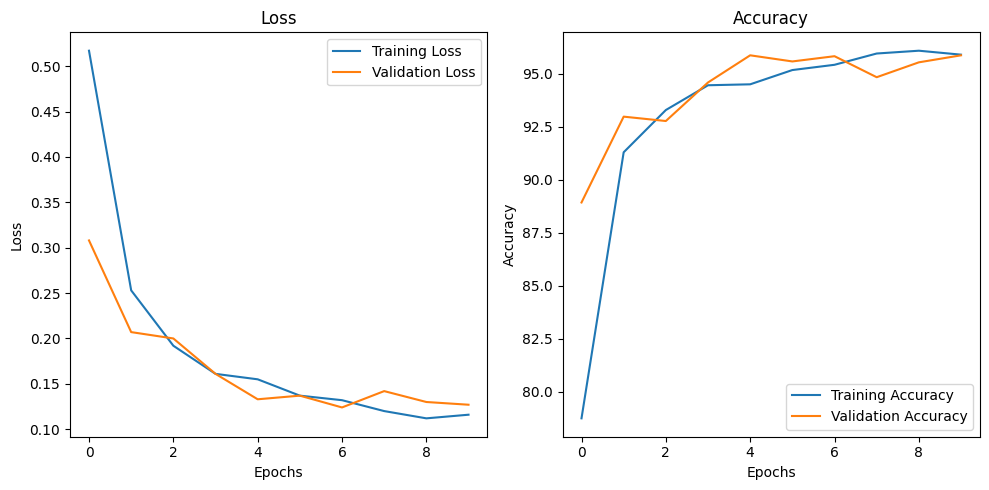

In [51]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 5))

axs[0].plot(total_los_train_plot, label = "Training Loss")
axs[0].plot(total_los_val_plot, label = "Validation Loss")
axs[0].set_title("Loss")
axs[0].legend()
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Loss")

axs[1].plot(total_acc_train_plot, label = "Training Accuracy")
axs[1].plot(total_acc_val_plot, label = "Validation Accuracy")
axs[1].set_title("Accuracy")
axs[1].legend()
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

In [52]:
def predict_image(image_path):
  image = Image.open(image_path).convert("RGB")
  image = transform(image).unsqueeze(0).to(device)
  print(image.shape)
  output = model(image)
  output = torch.argmax(output, axis = 1).item()
  output = label_encoder.inverse_transform([output])
  return output

In [56]:
predict_image("/content/tiger.jpg")



torch.Size([1, 3, 128, 128])


array(['wild'], dtype=object)

In [54]:
# Save the model
torch.save(model.state_dict(), "model.pth")
